In [1]:
import numpy as np
from argparse import Namespace
from solver.kolmogorov_flow import KolmogorovFlow2d
from generate_data import legacy_solver, gen_data
from prepare_data import shuffle_data, test_data, get_slice

In [ ]:
legacy_args = Namespace(
    outdir="./data_test",
    re=1000.0,
    res_x=256,
    T=1,             # trajectory 개수
    warmup=1.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=320,     # t축 픽셀 개수
    independent_ic=False,
)
legacy_solver(legacy_args)


  0%|          | 0/1 [00:00<?, ?it/s]

u0 finite: True u0 max: 0.26862299746318946 u0 std: 0.07985811159410783
100.0
99.9999
99.9998
99.9997
99.9996
99.9995
99.9994
99.9993
99.9992
99.9991
99.999
99.9989
99.9988
99.9987
99.9986
99.9985
99.9984
99.9983
99.9982
99.9981
99.998
99.9979
99.9978
99.9977
99.9976
99.9975
99.9974
99.9973
99.9972
99.9971
99.997
99.9969
99.9968
99.9967
99.9966
99.9965
99.9964
99.9963
99.9962
99.9961
99.996
99.9959
99.9958
99.9957
99.9956
99.9955
99.9954
99.9953
99.9952
99.9951
99.995
99.9949
99.9948
99.9947
99.9946
99.9945
99.9944
99.9943
99.9942
99.9941
99.994
99.9939
99.9938
99.9937
99.9936
99.9935
99.9934
99.9933
99.9932
99.9931
99.993
99.9929
99.9928
99.9927
99.9926
99.9925
99.9924
99.9923
99.9922
99.9921
99.992
99.9919
99.9918
99.9917
99.9916
99.9915
99.9914
99.9913
99.9912
99.9911
99.991
99.9909
99.9908
99.9907
99.9906
99.9905
99.9904
99.9903
99.9902
99.9901
99.99
99.9899
99.9898
99.9897
99.9896
99.9895
99.9894
99.9893
99.9892
99.9891
99.989
99.9889
99.9888
99.9887
99.9886
99.9885
99.9884
99.988

In [3]:
legacy_args = Namespace(
    outdir="./data_sequence",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=100.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=256,     # t축 픽셀 개수
    independent_ic=False,
)

legacy_solver(legacy_args)


39, time cost: 0.28408585500437766: 100%|██████████| 40/40 [58:21<00:00, 87.53s/it] 


In [4]:
legacy_args = Namespace(
    outdir="./data",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=100.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=256,     # t축 픽셀 개수
    independent_ic=True,
)

legacy_solver(legacy_args)


  0%|          | 0/40 [00:07<?, ?it/s]


KeyboardInterrupt: 

[[-0.56221652 -0.22284937 -0.238168   ... -1.63179731 -1.55193281
  -1.12331545]
 [-1.62076974 -1.01003838 -0.51048589 ... -1.53805065 -1.87440062
  -1.95297194]
 [-2.25706863 -2.03833532 -1.42839313 ... -1.38719869 -1.67570841
  -2.0523181 ]
 ...
 [-0.3199141  -0.84045243 -1.78205919 ...  0.5046311   0.27433324
  -0.01944458]
 [-0.05523634 -0.31444597 -0.71479058 ...  0.00622284  0.24943042
   0.18813729]
 [ 0.01895475 -0.12707853 -0.34690738 ... -1.03268576 -0.5640254
  -0.12429428]]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan n

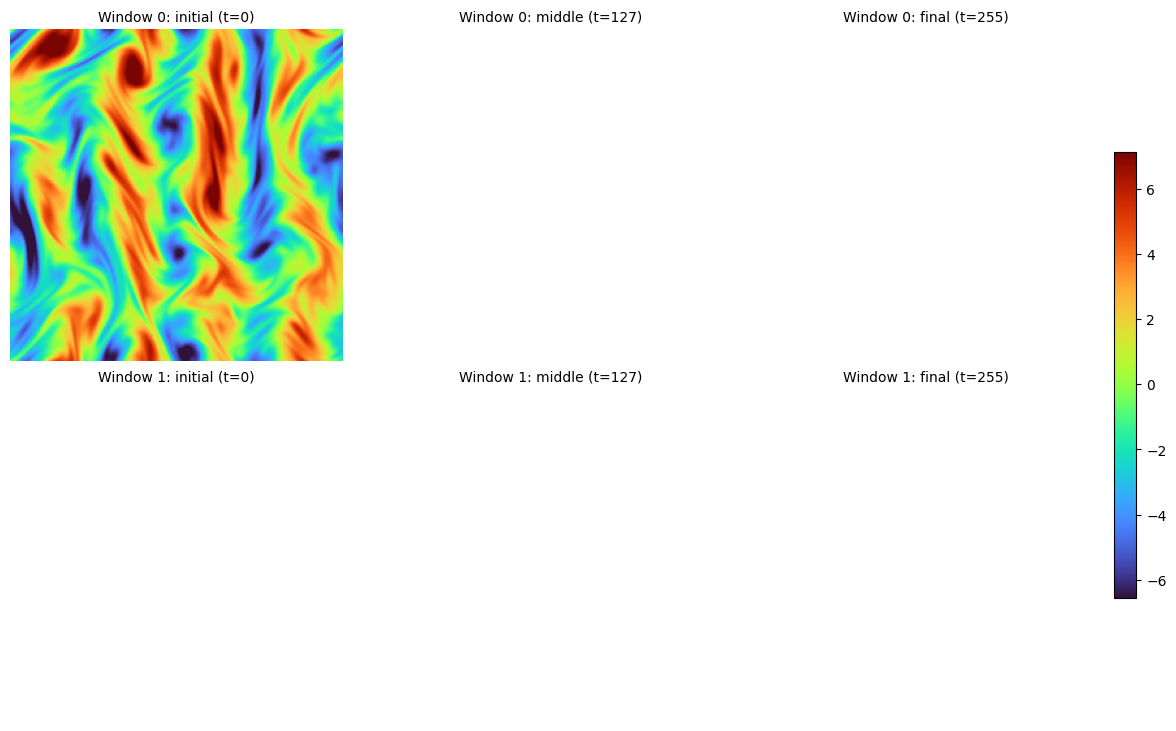

In [23]:
import numpy as np
import matplotlib.pyplot as plt

def plot_init_mid_final_2d_strict(
    npy_path,
    window_idxs=None,
    cmap="turbo",
    origin="lower",
    robust_percentiles=(1, 99),
    mid_mode="lower",   # "lower": 127 (for 256), "upper": 128
):
    data = np.load(npy_path, mmap_mode="r")

    # (n_frames, H, W)도 허용
    if data.ndim == 3:
        data = data[None, ...]
    elif data.ndim != 4:
        raise ValueError(f"Expected 3D or 4D array, got {data.shape}")

    T, n_frames, H, W = data.shape

    if window_idxs is None:
        window_idxs = list(range(T))
    else:
        window_idxs = [int(i) for i in window_idxs if 0 <= int(i) < T]
    if len(window_idxs) == 0:
        raise ValueError("No valid window indices.")

    t0 = 0
    tlast = n_frames - 1
    tmid = (n_frames - 1) // 2 if mid_mode == "lower" else n_frames // 2

    time_idxs = [t0, tmid, tlast]
    time_titles = [f"initial (t={t0})", f"middle (t={tmid})", f"final (t={tlast})"]

    # 공통 vmin/vmax (NaN 방지 포함)
    vals = []
    for widx in window_idxs:
        for t in time_idxs:
            frame = np.asarray(data[widx, t, :, :])
            if frame.shape != (H, W):
                raise ValueError(
                    f"Indexing produced non-2D frame: window={widx}, t={t}, frame.shape={frame.shape}"
                )
            vals.append(frame.ravel())
    vals = np.concatenate(vals)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        raise ValueError("All values are non-finite (NaN/Inf).")

    vmin, vmax = np.percentile(vals, robust_percentiles)
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        vmin, vmax = float(vals.min()), float(vals.max())
    
    nrows = len(window_idxs)
    fig, axes = plt.subplots(
        nrows=nrows, ncols=3,
        figsize=(12, 3.6 * nrows),
        constrained_layout=True,
        squeeze=False
    )

    last_im = None
    for r, widx in enumerate(window_idxs):
        for c, (t, title) in enumerate(zip(time_idxs, time_titles)):
            
            ax = axes[r, c]
            frame = np.asarray(data[widx, t, :, :])  # <-- 핵심: 직접 인덱싱
            print(frame)
            last_im = ax.imshow(frame, cmap=cmap, origin=origin, vmin=vmin, vmax=vmax)
            ax.set_title(f"Window {widx}: {title}", fontsize=10)
            ax.axis("off")

    # 공통 컬러바 (axes 전체에 붙이기: 레이아웃 덜 깨짐)
    fig.colorbar(last_im, ax=axes, fraction=0.02, pad=0.02)

    plt.show()


# Example
plot_init_mid_final_2d_strict("./data_test/NS-Re1000_T255.npy", mid_mode="lower")


In [ ]:
ns_args = Namespace(
    outdir='./data_ns',
    re=40.0,
    x_res=512,
    x_sub=2,
    T=10,
    t_res=128,
    batchsize=4,
    num_batchs=1,
    seed=0
)
ns_paths = gen_data(ns_args)
print('NS dataset files:', ns_paths)


NameError: name 'ns_args' is not defined